# Reconstrução dos períodos sem cadastro

**Projeto Integrador IV (UNIVESP).** Continuação dos notebooks 01 a 03.

A análise exploratória mostrou que a base do sistema tem meses inteiros sem cadastro: só 12 meses estão completos. Não houve tempo de obter os dados oficiais da Defesa Civil. Por isso, este notebook **estima** quantas ocorrências houve nesses períodos, por dia e por distrito, e verifica se essa base reconstruída melhora a previsão de demanda.

**A regra que torna a reconstrução defensável:** os dados estimados entram **só no treino**. Toda métrica de desempenho é calculada **apenas em semanas reais**. Se a reconstrução ajudar, o ganho aparece em dados reais. Se não ajudar, isso também aparece.

Etapas:

1. Definir os períodos sem cadastro e o que se sabe sobre cada um.
2. Ajustar o modelo de reconstrução e **validá-lo** escondendo meses reais.
3. Reconstruir a série em várias versões (imputação múltipla).
4. Comparar a análise exploratória **antes e depois** da reconstrução.
5. Retreinar a previsão de demanda com a base reconstruída e testar nas mesmas semanas reais do notebook 02.

O código está em `ml/reconstrucao.py`.

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("defesa2.0").exists():
        !git clone -q https://github.com/allanwds/defesa2.0.git
    RAIZ = Path("defesa2.0").resolve()
else:
    RAIZ = Path.cwd().resolve()
    while not (RAIZ / "ml").is_dir() and RAIZ != RAIZ.parent:
        RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ml import modelos as M
from ml.chuva import chuva_diaria
from ml.dados import DIR_DADOS, carregar_ocorrencias
from ml.features import VARIAVEIS_REGRESSAO, painel_semanal, painel_semanal_continuo
from ml.limpeza import limpar, marcar_periodos, ocorrencias_validas
from ml.reconstrucao import LACUNAS, ModeloDemandaDiaria, contagens_diarias_reais, reconstruir

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:.2f}")

TEXTO, TEXTO_SEC, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#c9c8c2"
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRADE,
    "axes.labelcolor": TEXTO_SEC,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "xtick.color": TEXTO_SEC,
    "ytick.color": TEXTO_SEC,
    "legend.frameon": False,
    "font.size": 10,
})


def num(v, casas=2):
    return f"{v:.{casas}f}".replace(".", ",")


INICIO_VALIDACAO = pd.Timestamp("2025-04-01")
INICIO_TESTE = pd.Timestamp("2025-07-01")
VERSOES = 10

oc = marcar_periodos(ocorrencias_validas(limpar(carregar_ocorrencias())))
diaria = chuva_diaria([2024, 2025, 2026])
reais = contagens_diarias_reais(oc)

## 1. Os períodos sem cadastro

Os períodos sem cadastro não são todos iguais. Em um deles, a numeração oficial das ocorrências revela **quantas** ocorrências houve, embora elas não estejam no sistema.

In [2]:
pd.DataFrame([{
    "início": pd.Timestamp(l["inicio"]).strftime("%d/%m/%Y"),
    "fim": pd.Timestamp(l["fim"]).strftime("%d/%m/%Y"),
    "dias": len(pd.date_range(l["inicio"], l["fim"])),
    "total conhecido": "não" if l["total"] is None else f"{l['total']} ocorrências",
    "como é reconstruído": "simulação pelo modelo" if l["total"] is None else "o total é distribuído entre os dias pelo modelo",
} for l in LACUNAS])

,início,fim,dias,total conhecido,como é reconstruído
0,01/03/2024,31/12/2024,306,não,simulação pelo modelo
1,08/10/2025,31/12/2025,85,não,simulação pelo modelo
2,04/02/2026,08/05/2026,94,251 ocorrências,o total é distribuído entre os dias pelo modelo


- **Março a dezembro de 2024 e 8 de outubro a dezembro de 2025:** não há nenhuma informação sobre as ocorrências, apenas a chuva diária. O modelo simula as contagens.
- **4 de fevereiro a 8 de maio de 2026:** o cadastro parou no número 127 e voltou com os números 379 e 380. As **251 ocorrências** intermediárias existiram. O modelo apenas decide **em que dias** elas provavelmente aconteceram.
- Pequenas falhas dentro dos períodos completos (cerca de 23 números ausentes em 2025) foram ignoradas, porque representam menos de 5% do período.

## 2. O modelo de reconstrução

Para cada dia e distrito, o modelo estima o número esperado de ocorrências a partir de:

- **distrito;**
- **dia da semana**, que capta a escala de atendimento;
- **verão** e **estação chuvosa;**
- **chuva acumulada** em 1, 3, 7 e 14 dias, da estação do INMET em Interlagos (notebook 03).

A contagem segue uma distribuição **binomial negativa**: além da média, ela reproduz a variabilidade dos dados reais, com dias calmos e dias de pico. O modelo é ajustado **só com dias reais anteriores ao período de teste** (antes de 01/07/2025).

In [3]:
treino_rec = reais[reais["data"] < INICIO_TESTE]
modelo_rec = ModeloDemandaDiaria(diaria).fit(treino_rec)
coef = pd.Series(modelo_rec.glm_.coef_, index=modelo_rec.variaveis(treino_rec).columns)

efeitos = {
    "Jardim São Luís (vs. Jardim Ângela)": np.exp(coef["sao_luis"]),
    "verão (jan–fev)": np.exp(coef["verao"]),
    "estação chuvosa (out–mar)": np.exp(coef["estacao_chuvosa"]),
    **{f"{d} (vs. domingo)": np.exp(coef[d]) for d in ["seg", "ter", "qua", "qui", "sex", "sab"]},
    **{f"50 mm de chuva em {n} dia(s) (vs. nenhuma)": np.exp(coef[f"log_chuva_{n}d"] * np.log1p(50)) for n in (1, 3, 7, 14)},
}
print(f"Ajustado com {treino_rec['data'].nunique()} dias reais. Sobredispersão α = {num(modelo_rec.alpha_)}")
pd.Series(efeitos, name="multiplica a média diária por").to_frame()

Ajustado com 241 dias reais. Sobredispersão α = 1,24


,multiplica a média diária por
Jardim São Luís (vs. Jardim Ângela),0.82
verão (jan–fev),1.22
estação chuvosa (out–mar),1.26
seg (vs. domingo),4.85
ter (vs. domingo),4.71
qua (vs. domingo),6.48
qui (vs. domingo),2.86
sex (vs. domingo),6.74
sab (vs. domingo),2.36
50 mm de chuva em 1 dia(s) (vs. nenhuma),0.92


Cada número indica por quanto a média diária de ocorrências é multiplicada naquela condição, mantendo as demais iguais.

- **Dia da semana:** o efeito é enorme. Quartas e sextas têm mais de 6 vezes a média de domingo, o que reforça que a data é a do atendimento.
- **Chuva:** a de 14 dias é a que mais pesa, coerente com o atraso entre chuva e atendimento visto no notebook 03. Com 50 mm em 14 dias, a média diária fica cerca de 2,2 vezes maior, o mesmo tamanho de efeito medido de forma independente no notebook 03 (razão de 2,0).
- **Sobredispersão (α):** um α acima de 1 indica que as contagens variam bem mais do que uma distribuição de Poisson preveria. Por isso a binomial negativa é necessária.

## 3. O método funciona? Teste de mascaramento

Antes de usar o modelo nos buracos de verdade, ele é testado em meses cujo valor real conhecemos. Cada mês real anterior ao teste é **escondido**, o modelo é ajustado com os demais meses e reconstrói o mês escondido em 200 simulações. Depois, compara-se com o que de fato aconteceu.

A referência simples é preencher cada semana com a média semanal do distrito nos meses usados no ajuste.

In [4]:
rng = np.random.default_rng(M.SEMENTE)
treino_rec = treino_rec.assign(mes=treino_rec["data"].dt.to_period("M"),
                               semana=treino_rec["data"].dt.to_period("W-SUN"))
linhas = []
for mes in treino_rec["mes"].unique():
    ajuste, alvo = treino_rec[treino_rec["mes"] != mes], treino_rec[treino_rec["mes"] == mes]
    modelo = ModeloDemandaDiaria(diaria).fit(ajuste)
    sims = np.array([modelo.simular(alvo, rng) for _ in range(200)])  # simulações × dias
    por_semana = pd.DataFrame(sims.T, index=alvo.index).groupby([alvo["semana"], alvo["distrito"]]).sum()
    real_semana = alvo.groupby(["semana", "distrito"])["ocorrencias"].sum()
    media_ajuste = ajuste.groupby("distrito")["ocorrencias"].mean() * 7
    ingenua = real_semana.index.get_level_values("distrito").map(media_ajuste)
    total_sim = sims.sum(axis=1)
    linhas.append({
        "mês escondido": str(mes),
        "real": alvo["ocorrencias"].sum(),
        "reconstruído (mediana)": np.median(total_sim),
        "intervalo 90%": f"{np.quantile(total_sim, 0.05):.0f} a {np.quantile(total_sim, 0.95):.0f}",
        "erro semanal: modelo": (por_semana.median(axis=1) - real_semana).abs().mean(),
        "erro semanal: média simples": (real_semana - ingenua).abs().mean(),
        "semanas dentro do intervalo 90%": ((real_semana >= por_semana.quantile(0.05, axis=1))
                                            & (real_semana <= por_semana.quantile(0.95, axis=1))).mean(),
    })
mascaramento = pd.DataFrame(linhas).set_index("mês escondido")
resumo = mascaramento[["erro semanal: modelo", "erro semanal: média simples", "semanas dentro do intervalo 90%"]].mean()
print(f"Erro semanal médio: modelo {num(resumo.iloc[0])} × média simples {num(resumo.iloc[1])} "
      f"({1 - resumo.iloc[0] / resumo.iloc[1]:.0%} menor)")
print(f"Semanas reais dentro do intervalo de 90%: {resumo.iloc[2]:.0%} (o ideal é 90%)")
mascaramento

Erro semanal médio: modelo 3,68 × média simples 4,80 (23% menor)
Semanas reais dentro do intervalo de 90%: 85% (o ideal é 90%)


,real,reconstruído (mediana),intervalo 90%,erro semanal: modelo,erro semanal: média simples,semanas dentro do intervalo 90%
mês escondido,,,,,,
2024-01,63,129.50,93 a 168,5.35,2.39,0.90
2024-02,74,95.00,70 a 128,3.40,3.88,0.80
2025-01,57,74.00,51 a 104,3.20,3.53,0.90
2025-02,131,48.00,35 a 60,9.30,10.54,0.70
2025-03,43,40.00,27 a 58,1.67,4.16,0.92
2025-04,57,53.00,38 a 71,3.20,4.14,0.80
2025-05,34,24.00,15 a 36,2.10,4.35,0.80
2025-06,26,38.00,26 a 54,1.25,5.45,1.00


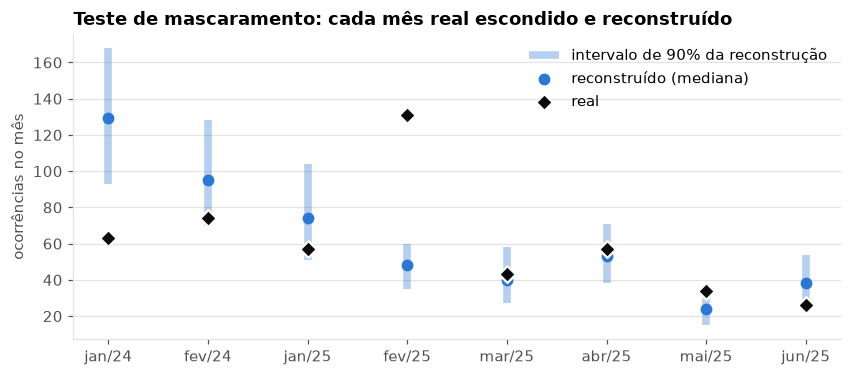

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(mascaramento))
baixo = mascaramento["intervalo 90%"].str.split(" a ").str[0].astype(float)
alto = mascaramento["intervalo 90%"].str.split(" a ").str[1].astype(float)
ax.vlines(x, baixo, alto, color=AZUL, linewidth=5, alpha=0.35, label="intervalo de 90% da reconstrução")
ax.scatter(x, mascaramento["reconstruído (mediana)"], s=45, color=AZUL, zorder=3, label="reconstruído (mediana)")
ax.scatter(x, mascaramento["real"], s=60, color=TEXTO, marker="D", edgecolor="white", linewidth=1.5, zorder=4,
           label="real")
ax.set_xticks(x, [f"{MESES[int(m[5:]) - 1]}/{m[2:4]}" for m in mascaramento.index])
ax.set_ylabel("ocorrências no mês")
ax.set_title("Teste de mascaramento: cada mês real escondido e reconstruído")
ax.legend(loc="upper right")
plt.show()

- O modelo erra cerca de **um quarto a menos** que a média simples.
- Seus intervalos de 90% contêm o valor real em **85%** das semanas, perto dos 90% ideais. A incerteza está razoavelmente calibrada, só um pouco otimista.
- Os maiores erros estão nos meses atípicos. Janeiro de 2024 teve 378 mm de chuva e poucas ocorrências cadastradas. Fevereiro de 2025 teve o maior pico de ocorrências com chuva moderada no próprio mês.

A chuva explica a tendência, mas não todos os picos. Isso fica registrado como limitação da reconstrução.

## 4. Reconstrução em várias versões

São geradas várias versões da série completa. Em cada uma, o modelo é reajustado numa reamostragem das semanas reais e as contagens são sorteadas de novo. As diferenças entre as versões mostram a incerteza da reconstrução: nenhuma versão é "a verdadeira".

In [6]:
serie = reconstruir(oc, diaria, ajuste_ate=INICIO_TESTE, versoes=VERSOES, semente=M.SEMENTE)

anual = serie.groupby(["versao", serie["data"].dt.year, "origem"])["ocorrencias"].sum().unstack(fill_value=0)
anual["total"] = anual.sum(axis=1)
resumo_anual = anual.groupby(level=1).agg(["median", "min", "max"]).round(0).astype(int)
resumo_anual.index.name = "ano"
print("Ocorrências por ano (mediana, mínimo e máximo entre as versões):")
resumo_anual

Ocorrências por ano (mediana, mínimo e máximo entre as versões):


origem estimado             real            total          
         median  min  max median  min  max median  min  max
ano                                                        
2024        404  347  458    137  137  137    541  484  595
2025        146  100  197    506  506  506    652  606  703
2026        253  253  253    124  124  124    377  377  377

- **2024:** a reconstrução estima cerca de 400 ocorrências de março a dezembro, o que leva o ano a cerca de 540 ocorrências.
- **2025:** fecha com cerca de 650.
- **2026 até 8 de maio:** o total é fixo, 253 estimadas mais 124 reais, porque vem da numeração oficial.

Os totais anuais de 2024 e 2025 ficam na mesma ordem de grandeza, o que é um sinal de coerência.

## 5. Análise exploratória: antes × depois da reconstrução

### 5.1 A série mensal

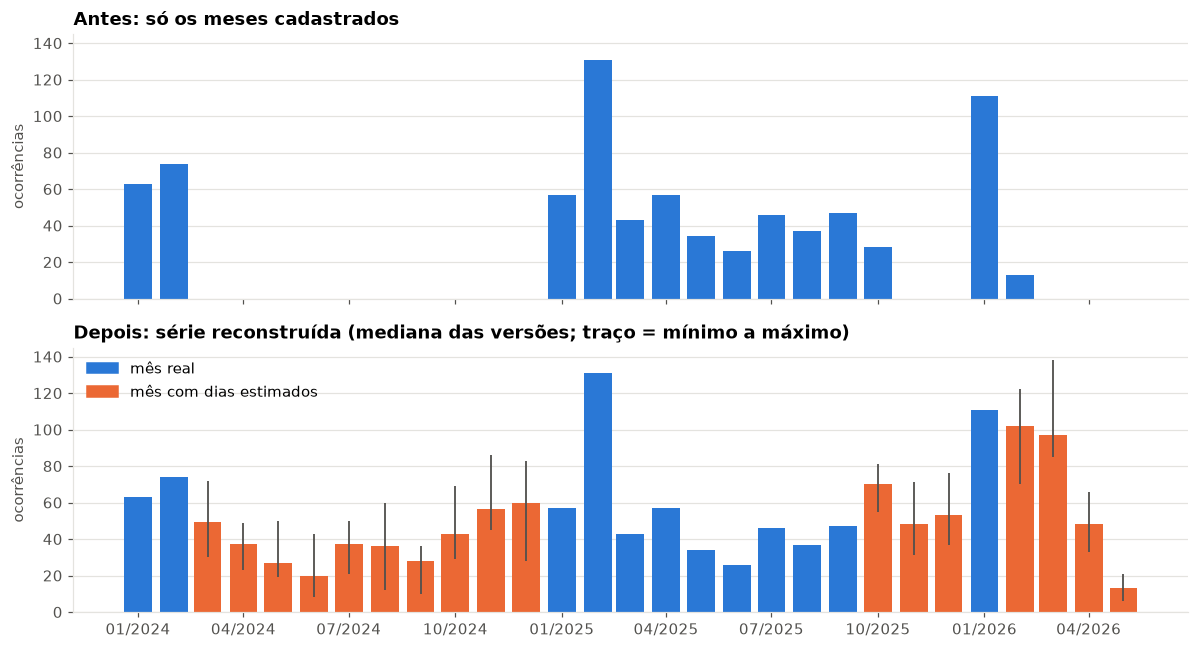

In [7]:
def mensal(df):
    return df.groupby(df["data"].dt.to_period("M"))["ocorrencias"].sum()

antes = mensal(reais)
por_versao = serie.groupby(["versao", serie["data"].dt.to_period("M")])["ocorrencias"].sum().unstack(0)
estimado_mes = serie[serie["origem"] == "estimado"].groupby(serie["data"].dt.to_period("M")).size() > 0
meses = por_versao.index
x = meses.to_timestamp()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, sharey=True)
ax1.bar(antes.index.to_timestamp(), antes.values, width=24, color=AZUL)
ax1.set_title("Antes: só os meses cadastrados")
ax1.set_ylabel("ocorrências")
cores = np.where(estimado_mes.reindex(meses, fill_value=False), LARANJA, AZUL)
ax2.bar(x, por_versao.median(axis=1), width=24, color=cores)
ax2.vlines(x, por_versao.min(axis=1), por_versao.max(axis=1), color=TEXTO_SEC, linewidth=1.2)
ax2.set_title("Depois: série reconstruída (mediana das versões; traço = mínimo a máximo)")
ax2.set_ylabel("ocorrências")
ax2.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=AZUL), plt.Rectangle((0, 0), 1, 1, color=LARANJA)],
           labels=["mês real", "mês com dias estimados"], loc="upper left")
ax2.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
fig.tight_layout()
plt.show()

A série passa a ser contínua. Os meses reconstruídos seguem o regime de chuva: sobem na estação chuvosa (fim de 2024 e começo de 2026) e caem no inverno.

A última barra (maio de 2026) cobre só até o dia 8. Os traços verticais mostram a incerteza. Ela é maior nos meses totalmente simulados e nula nos meses reais. Em fevereiro a maio de 2026, o total do período é fixo, mas a divisão entre os meses varia de uma versão para outra.

### 5.2 Sazonalidade ao longo do ano inteiro

Antes da reconstrução, não havia nenhum dado de novembro e dezembro, e outubro tinha uma única semana. Agora é possível desenhar o ano inteiro, com uma ressalva: os meses sem nenhum dado real refletem o modelo, não observações.

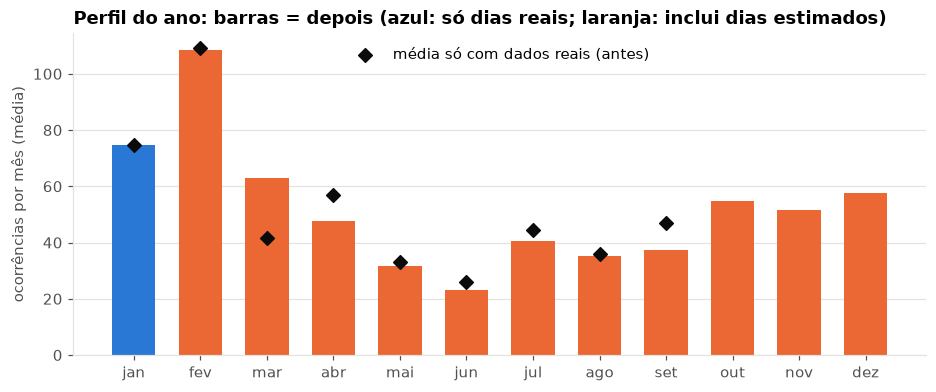

In [8]:
mediana = serie.groupby(["versao", "data", "origem"])["ocorrencias"].sum().reset_index()
mediana["mes"] = mediana["data"].dt.month
media_mes = mediana.groupby(["versao", "mes"])["ocorrencias"].sum() / mediana.groupby(["versao", "mes"])["data"].nunique() * 30
perfil = media_mes.groupby(level="mes").median()
dias_reais_mes = reais.groupby(reais["data"].dt.month)["data"].nunique()
real_mes = reais.groupby(reais["data"].dt.month)["ocorrencias"].sum() / dias_reais_mes * 30
real_mes = real_mes[dias_reais_mes >= 28]  # meses com pelo menos um mês inteiro de dados reais
fracao_real = (serie[(serie["versao"] == 0)].groupby(serie["data"].dt.month)["origem"]
               .apply(lambda s: (s == "real").mean()))

fig, ax = plt.subplots(figsize=(10, 3.8))
cores = [AZUL if f == 1 else LARANJA for f in fracao_real.reindex(range(1, 13), fill_value=0)]
ax.bar(range(1, 13), perfil.reindex(range(1, 13)), width=0.65, color=cores)
ax.scatter(real_mes.index, real_mes.values, color=TEXTO, marker="D", s=40, zorder=3, label="média só com dados reais (antes)")
ax.set_xticks(range(1, 13), MESES)
ax.set_ylabel("ocorrências por mês (média)")
ax.set_title("Perfil do ano: barras = depois (azul: só dias reais; laranja: inclui dias estimados)")
ax.legend(loc="upper center")
plt.show()

- O perfil confirma a **sazonalidade**: janeiro e fevereiro concentram a demanda, que cai de abril a setembro e volta a subir a partir de outubro.
- Janeiro só tem dados reais (azul), e a barra coincide com o losango (a média antes da reconstrução). Fevereiro inclui os dias estimados de 2026, mas fica praticamente igual à média real.
- De março a setembro, as barras misturam o ano real (2025) com os anos estimados (2024 e 2026) e ficam próximas dos losangos. A maior diferença é em março, puxado para cima pelas 251 ocorrências de 2026, que caem em boa parte nesse mês.
- Outubro a dezembro quase não têm dados reais. Essas barras são **estimativas do modelo**, guiadas pela chuva real desses meses, e não observações.

### 5.3 A variabilidade das semanas reconstruídas

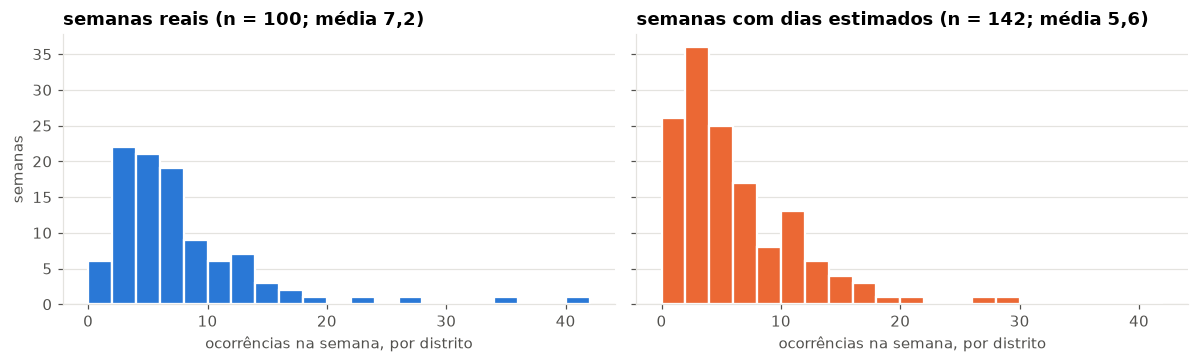

In [9]:
semanas_v0 = painel_semanal_continuo(serie[serie["versao"] == 0])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
faixas = np.arange(0, semanas_v0["ocorrencias"].max() + 3, 2)
for ax, (real, nome, cor) in zip(axes, [(True, "semanas reais", AZUL), (False, "semanas com dias estimados", LARANJA)]):
    dados = semanas_v0.loc[semanas_v0["semana_real"] == real, "ocorrencias"]
    ax.hist(dados, bins=faixas, color=cor, edgecolor="white", linewidth=1.5)
    ax.set_title(f"{nome} (n = {len(dados)}; média {num(dados.mean(), 1)})")
    ax.set_xlabel("ocorrências na semana, por distrito")
axes[0].set_ylabel("semanas")
fig.tight_layout()
plt.show()

As semanas estimadas têm uma distribuição parecida com a das reais: muitas semanas calmas e algumas com picos. Isso é efeito da binomial negativa. A média é menor (5,6 contra 7,2) porque a maior parte das semanas estimadas cai na estação seca de 2024, enquanto as semanas reais concentram dois verões. Uma imputação pela média produziria semanas todas iguais e esconderia os picos, que são justamente o que importa para a Defesa Civil.

## 6. A base reconstruída melhora a previsão de demanda?

O experimento repete o protocolo do notebook 02:

- **Treino:** todas as semanas anteriores à semana prevista, agora com as estimadas incluídas.
- **Validação:** as mesmas semanas **reais** de abril a junho de 2025, usadas para escolher `min_samples_leaf`.
- **Teste:** as mesmas 32 previsões **reais** do notebook 02 (julho a início de outubro de 2025 e janeiro de 2026).
- **Previsão final:** a média das previsões das versões (imputação múltipla).

Esta etapa leva alguns minutos.

In [10]:
painel_real = painel_semanal(oc)
semanas_validacao = np.sort(painel_real.loc[(painel_real["semana"] >= INICIO_VALIDACAO)
                                            & (painel_real["semana"] < INICIO_TESTE), "semana"].unique())
semanas_teste = np.sort(painel_real.loc[painel_real["semana"] >= INICIO_TESTE, "semana"].unique())
paineis = {v: painel_semanal_continuo(serie[serie["versao"] == v]) for v in range(VERSOES)}


def previsao_combinada(semanas, fabricas):
    # Previsão passo a passo em cada versão e média entre as versões.
    por_versao = [M.previsao_passo_a_passo(paineis[v], semanas, fabricas, VARIAVEIS_REGRESSAO) for v in range(VERSOES)]
    combinada = por_versao[0][["semana", "distrito", "ocorrencias"]].copy()
    for nome in fabricas:
        combinada[nome] = np.mean([p[nome].to_numpy() for p in por_versao], axis=0)
    return combinada, por_versao


candidatos = {str(n): (lambda n=n: M.regressor(n)) for n in (1, 3, 5, 10, 20)}
val, _ = previsao_combinada(semanas_validacao, candidatos)
mae_val = pd.Series({int(n): M.metricas_regressao(val["ocorrencias"], val[n])["MAE"] for n in candidatos},
                    name="MAE na validação")
FOLHA = int(mae_val.idxmin())
print(f"Escolhido na validação: min_samples_leaf={FOLHA}")
mae_val.to_frame()

Escolhido na validação: min_samples_leaf=20


,MAE na validação
1,2.50
3,2.56
5,2.59
10,2.61
20,2.48


In [11]:
teste_rec, teste_versoes = previsao_combinada(semanas_teste, {"reconstruída": lambda: M.regressor(FOLHA),
                                                              "média móvel": M.MediaMovel})
original = M.avaliar_regressao(painel_real, VARIAVEIS_REGRESSAO, INICIO_VALIDACAO, INICIO_TESTE)
comparacao = original["teste"][["semana", "distrito", "ocorrencias", "previsto", "media4"]].merge(
    teste_rec[["semana", "distrito", "reconstruída", "média móvel"]], on=["semana", "distrito"])

erro = {
    "Random Forest, só dados reais (notebook 02)": (comparacao["ocorrencias"] - comparacao["previsto"]).abs(),
    f"Random Forest, treino reconstruído (min_samples_leaf={FOLHA})": (comparacao["ocorrencias"] - comparacao["reconstruída"]).abs(),
    "média móvel, só dados reais": (comparacao["ocorrencias"] - comparacao["media4"]).abs(),
    "média móvel, com semanas reconstruídas": (comparacao["ocorrencias"] - comparacao["média móvel"]).abs(),
}
trecho = np.where(comparacao["semana"].dt.year == 2026, "jan/2026", "jul–out/2025")
tabela = pd.DataFrame({nome: {"MAE (teste inteiro)": e.mean(), **e.groupby(trecho).mean().add_prefix("MAE ").to_dict()}
                       for nome, e in erro.items()}).T

e_orig = erro["Random Forest, só dados reais (notebook 02)"].to_numpy()
e_rec = erro[f"Random Forest, treino reconstruído (min_samples_leaf={FOLHA})"].to_numpy()
ic = M.intervalo_bootstrap(lambda i: e_rec[i].mean() - e_orig[i].mean(), len(e_rec), grupos=comparacao["semana"])
mae_versoes = [M.metricas_regressao(p["ocorrencias"], p["reconstruída"])["MAE"] for p in teste_versoes]
print(f"Diferença de MAE (reconstruído − só reais): {num(e_rec.mean() - e_orig.mean())} "
      f"[IC 95%: {num(ic[0])}; {num(ic[1])}]")
print(f"MAE de cada versão isolada: de {num(min(mae_versoes))} a {num(max(mae_versoes))}")
tabela

Diferença de MAE (reconstruído − só reais): 0,23 [IC 95%: -0,27; 0,74]
MAE de cada versão isolada: de 3,29 a 3,67


,MAE (teste inteiro),MAE jan/2026,MAE jul–out/2025
"Random Forest, só dados reais (notebook 02)",3.17,4.03,2.97
"Random Forest, treino reconstruído (min_samples_leaf=20)",3.41,5.49,2.92
"média móvel, só dados reais",3.59,5.56,3.13
"média móvel, com semanas reconstruídas",3.86,7.02,3.13


In [12]:
fim_2025 = paineis[0][(paineis[0]["semana"] >= "2025-11-24") & (paineis[0]["semana"] <= "2026-01-26")]
fim_2025.pivot(index="semana", columns="distrito", values="ocorrencias").assign(
    **{"semana real?": fim_2025.groupby("semana")["semana_real"].first()}).rename_axis(None, axis=1)

,Jardim São Luís,Jardim Ângela,semana real?
semana,,,
2025-11-24,7,3,False
2025-12-01,13,6,False
2025-12-08,13,16,False
2025-12-15,7,7,False
2025-12-22,4,1,False
2025-12-29,2,3,False
2026-01-05,6,11,True
2026-01-12,16,9,True
2026-01-19,14,23,True


**Leitura do resultado:**

- **Julho a outubro de 2025:** o treino reconstruído dá praticamente o mesmo erro do modelo só com dados reais.
- **Janeiro de 2026:** o erro aumenta. As semanas reconstruídas do fim de dezembro saíram baixas (período de festas, pouca chuva), e o modelo, que se apoia nas semanas anteriores, subestimou o salto real de janeiro. A média móvel sofre o mesmo efeito.
- **No geral:** a diferença não é estatisticamente significativa. O intervalo de confiança inclui o zero, mas aponta mais para piora do que para melhora.

Na validação (abril a junho de 2025), o treino reconstruído tinha ido muito bem (MAE perto de 2,5, contra 3,2 no notebook 02). A melhora não se repetiu no teste. É exatamente por isso que a regra "testar só em dados reais" existe: sem ela, teríamos declarado um ganho que não existe.

**Por que a reconstrução não ajuda a previsão?** Ela não traz informação nova. As semanas estimadas são geradas a partir da chuva e do calendário, que o modelo de previsão já poderia usar diretamente. O que a reconstrução acrescenta é ruído plausível, e esse ruído entra nas defasagens que o modelo usa para prever.

## 7. Conclusões

### Resultado

| Pergunta | Resposta |
|---|---|
| O método de reconstrução funciona? | **Sim, com limites.** Erra 23% menos que a média simples, e os intervalos de 90% contêm o valor real em 85% das semanas. Falha nos meses atípicos, em que a chuva não explica o volume |
| A base fica contínua? | **Sim.** São 121 semanas por distrito, de janeiro de 2024 a maio de 2026, com 10 versões para representar a incerteza |
| A previsão de demanda melhora? | **Não.** O MAE no teste real foi de 3,41, contra 3,17 do modelo treinado só com dados reais (diferença de +0,23, IC 95% de -0,27 a 0,74). O erro é igual de julho a outubro e pior em janeiro de 2026 |

**Conclusão:** ampliar o treino com dados reconstruídos não melhora a previsão. O modelo de melhor desempenho continua sendo o do notebook 02, treinado só com dados reais. A base reconstruída serve à análise exploratória (série contínua e perfil anual), sempre identificada como estimativa. Ela não deve ser usada para medir o desempenho de modelos nem tratada como dado oficial.

In [13]:
saida = DIR_DADOS / "serie_reconstruida.csv"
serie.to_csv(saida, index=False)

faixa = serie.groupby(["data", "distrito", "origem"])["ocorrencias"].agg(
    mediana="median", minimo="min", maximo="max").reset_index()
saida_resumo = DIR_DADOS / "serie_reconstruida_resumo.csv"
faixa.to_csv(saida_resumo, index=False)
print(f"Todas as versões: {saida.relative_to(RAIZ)} ({len(serie)} linhas)")
print(f"Resumo por dia (mediana, mínimo, máximo): {saida_resumo.relative_to(RAIZ)} ({len(faixa)} linhas)")

Todas as versões: ml/dados/serie_reconstruida.csv (17180 linhas)
Resumo por dia (mediana, mínimo, máximo): ml/dados/serie_reconstruida_resumo.csv (1718 linhas)
